# Task 4: acople de una epidemia (SIR) al hospital
CC2017 Modelación y Simulación, UVG · Hoja de Trabajo 7 · Grupo 5.

| Inciso | Contenido | Estado |
|---|---|---|
| 4.1a | Integrar el SIR (200 días), graficar λepi(t) junto con λ y reportar el pico | **Hecho** (abajo) |
| 4.1b | Llegadas con λ(t) por adelgazamiento; 100 réplicas del modelo sin espera con las camas recomendadas en el Task 3.1 | **Hecho** (abajo) |
| 4.1c | Camas de contingencia para que los desviados durante la ola no superen 5 % | **Hecho** (abajo) |
| 4.1d | Dos fenómenos que el modelo de un solo sentido ignora y su efecto | Pendiente |

In [1]:
import sys, json, pathlib, math
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt

RAIZ = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from hospital_uci import teoria as T, simulador as S, sir

FIG, DAT = RAIZ / "resultados" / "figuras", RAIZ / "resultados" / "datos"
FIG.mkdir(parents=True, exist_ok=True); DAT.mkdir(parents=True, exist_ok=True)
AZUL, NARANJA, GRIS = "#0072B2", "#D55E00", "#6b7280"      # azul/naranja: distinguibles con daltonismo
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6, "font.size": 10,
                     "axes.titlesize": 11, "legend.frameon": False})
P = T.parametros_grupo(5)
lam, mu, c = P["lam"], P["mu"], P["c"]
RES = {}      # resultados numéricos de este notebook (se guardan en JSON al final)

def md_tabla(nombre, df, **kw):
    return df

## Task 4.1a — Modelo SIR y λ_epi(t)
$\dot S=-\beta SI/N$, $\dot I=\beta SI/N-\gamma I$, $\dot R=\gamma I$; $\lambda_{epi}(t)=p_h\,\beta\,S(t)I(t)/N$, $\lambda(t)=\lambda+\lambda_{epi}(t)$.
**Método:** Runge–Kutta clásico de 4.º orden con paso fijo (explícito, un paso, error global $O(\Delta t^4)$; el sistema es suave y no rígido). Se contrasta con DOP853 (tolerancia $10^{-11}$) y se reduce el paso.

In [2]:
SIRP = dict(beta=0.30, gamma=0.2, N=500_000, I0=100, R0=0, dias=200.0, p_h=0.0002)
assert 500_000 - 100 - 0 == 499_900
ref = sir.integrar_referencia(dt=0.01, **SIRP); pr = sir.pico(ref)
filas = []
for dt in [1.0, 0.5, 0.1, 0.05, 0.01]:
    cv = sir.integrar_sir(dt=dt, **SIRP); pk = sir.pico(cv)
    k_ref = np.round(cv["t"] / 0.01).astype(int)
    filas.append({"paso dt (días)": dt, "día del pico": pk["dia"], "pico λ_epi (pac/día)": pk["valor"],
                  "dif. rel. del pico vs referencia": abs(pk["valor"] - pr["valor"]) / pr["valor"],
                  "máx |λ_epi − referencia| (pac/día)": float(np.max(np.abs(cv["lambda_epi"] - ref["lambda_epi"][k_ref])))})
conv = pd.DataFrame(filas)
RES["sir_convergencia"] = conv.to_dict("records"); RES["sir_referencia_dop853"] = pr
md_tabla("sir_convergencia", conv.assign(**{"pico λ_epi (pac/día)": conv["pico λ_epi (pac/día)"].round(6), "dif. rel. del pico vs referencia": conv["dif. rel. del pico vs referencia"].map(lambda v: f"{v:.1e}"),
                                           "máx |λ_epi − referencia| (pac/día)": conv["máx |λ_epi − referencia| (pac/día)"].map(lambda v: f"{v:.1e}")}))
print("Referencia DOP853 (malla 0.01 d): pico", pr); conv

Referencia DOP853 (malla 0.01 d): pico {'dia': 68.64, 'valor': 1.3212683346356908}


,paso dt (días),día del pico,pico λ_epi (pac/día),dif. rel. del pico vs referencia,máx |λ_epi − referencia| (pac/día)
0,1.00,69.00,1.320895,2.827658e-04,1.587298e-06
1,0.50,68.50,1.321215,4.011067e-05,1.030323e-07
2,0.10,68.60,1.321265,2.864610e-06,1.766555e-10
3,0.05,68.65,1.321268,3.574350e-07,5.348605e-11
4,0.01,68.64,1.321268,2.276125e-12,5.041423e-11


R0 = β/γ = 1.50
Pico de λ_epi: 1.3213 pacientes/día en el día 68.6  (λ total = 5.1213; 34.8 % de la tasa base)
Pico de infectados I: 31578 en el día 73.3
Al día 200: S=208496, I=7.8, R=291496 (58.3 % de N)


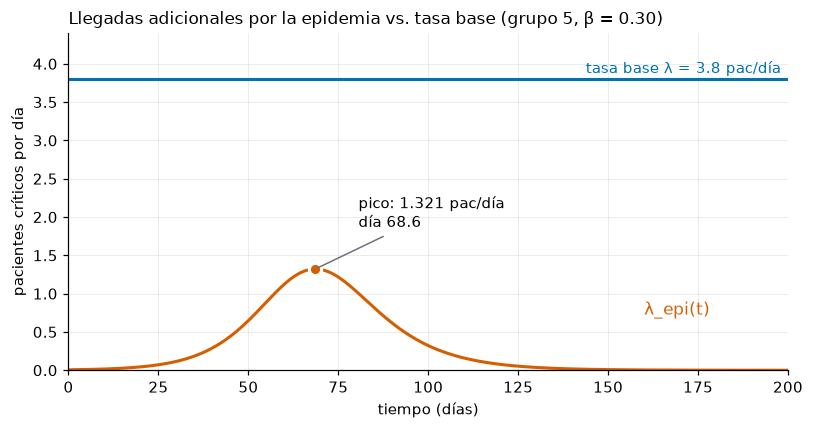

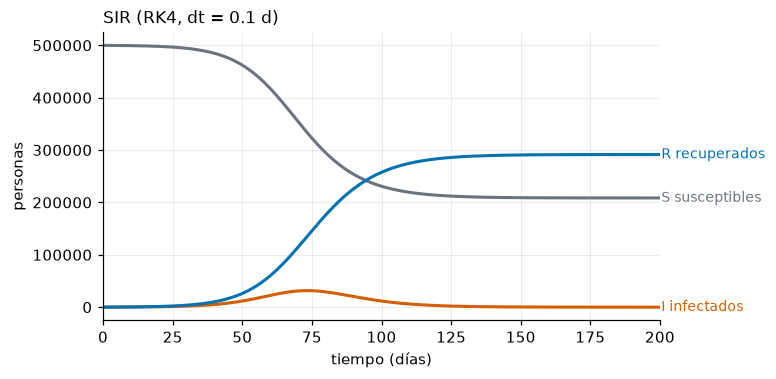

CSV escritos: ['sir_lambda_epi_diario.csv', 'sir_lambda_epi_dt0.1.csv']


In [3]:
cv = sir.integrar_sir(dt=0.1, **SIRP); pk = sir.pico(cv); ipk = sir.pico(cv, "I")
LAM_BASE = 3.8
pico_tot = LAM_BASE + pk["valor"]
RES["sir"] = {"R0": SIRP["beta"] / SIRP["gamma"], "pico_lambda_epi": pk, "pico_I": ipk, "lambda_total_en_pico": pico_tot,
              "fraccion_final_recuperados": float(cv["R"][-1] / SIRP["N"]), "S_final": float(cv["S"][-1]), "I_final": float(cv["I"][-1]),
              "lambda_epi_dia0": float(cv["lambda_epi"][0]), "razon_pico_sobre_base": pk["valor"] / LAM_BASE}
print(f"R0 = β/γ = {SIRP['beta']/SIRP['gamma']:.2f}")
print(f"Pico de λ_epi: {pk['valor']:.4f} pacientes/día en el día {pk['dia']:.1f}  (λ total = {pico_tot:.4f}; {100*pk['valor']/LAM_BASE:.1f} % de la tasa base)")
print(f"Pico de infectados I: {ipk['valor']:.0f} en el día {ipk['dia']:.1f}")
print(f"Al día 200: S={cv['S'][-1]:.0f}, I={cv['I'][-1]:.1f}, R={cv['R'][-1]:.0f} ({100*cv['R'][-1]/SIRP['N']:.1f} % de N)")
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(cv["t"], cv["lambda_epi"], color=NARANJA, lw=2); ax.axhline(LAM_BASE, color=AZUL, lw=2)
ax.text(198, LAM_BASE + 0.08, "tasa base λ = 3.8 pac/día", color=AZUL, ha="right"); ax.text(160, pk["valor"] * 0.55, "λ_epi(t)", color=NARANJA, fontsize=11)
ax.plot([pk["dia"]], [pk["valor"]], "o", color=NARANJA, ms=8, mec="white", mew=2)
ax.annotate(f"pico: {pk['valor']:.3f} pac/día\ndía {pk['dia']:.1f}", (pk["dia"], pk["valor"]), (pk["dia"] + 12, pk["valor"] + 0.55), arrowprops=dict(arrowstyle="-", color=GRIS))
ax.set_xlabel("tiempo (días)"); ax.set_ylabel("pacientes críticos por día"); ax.set_title("Llegadas adicionales por la epidemia vs. tasa base (grupo 5, β = 0.30)", loc="left")
ax.set_xlim(0, 200); ax.set_ylim(0, 4.4); plt.tight_layout(); plt.savefig(FIG / "fig_4_1a_lambda_epi.png", dpi=160); plt.show()
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for k, col, lab in [("S", GRIS, "S susceptibles"), ("I", NARANJA, "I infectados"), ("R", AZUL, "R recuperados")]:
    ax.plot(cv["t"], cv[k], color=col, lw=2); ax.text(200.5, cv[k][-1], lab, color=col, va="center", fontsize=9)
ax.set_xlim(0, 200); ax.set_xlabel("tiempo (días)"); ax.set_ylabel("personas"); ax.set_title("SIR (RK4, dt = 0.1 d)", loc="left")
plt.subplots_adjust(right=0.8); plt.savefig(FIG / "fig_4_1a_sir.png", dpi=160, bbox_inches="tight"); plt.show()
sir.exportar_csv(cv, str(DAT / "sir_lambda_epi_dt0.1.csv"), lam_base=LAM_BASE, cada=1)
cd = sir.integrar_sir(dt=1.0, **SIRP); sir.exportar_csv(cd, str(DAT / "sir_lambda_epi_diario.csv"), lam_base=LAM_BASE, cada=1)
chk = sir.cargar_csv(str(DAT / "sir_lambda_epi_dt0.1.csv"))
assert np.allclose(sir.lambda_epi_en(37.35, chk), np.interp(37.35, cv["t"], cv["lambda_epi"])) and len(chk["t_dias"]) == 2001
print("CSV escritos:", sorted(p.name for p in DAT.glob("sir_*.csv")))

In [4]:
(DAT / "task4_1a_resultados.json").write_text(json.dumps(RES, indent=2, default=lambda o: float(o) if hasattr(o, "__float__") else str(o), ensure_ascii=False))
print("Guardado: resultados/datos/task4_1a_resultados.json")

Guardado: resultados/datos/task4_1a_resultados.json


---
## Inciso 4.1b: simulación con llegadas variables λ(t)
Requisitos (hoja): generar las llegadas con $\lambda(t)=\lambda+\lambda_{epi}(t)$ por **adelgazamiento**, simular la variante **sin espera** con las camas recomendadas en el Task 3.1 (23) y, con 100 réplicas, reportar la probabilidad de bloqueo **en función del tiempo** y el total de pacientes desviados durante la ola, con su IC.

**Adelgazamiento (sesión):** se generan candidatos de un Poisson homogéneo de tasa $\lambda_{max}$ y cada candidato en $t$ se acepta con probabilidad $\lambda(t)/\lambda_{max}$. Se usa $\lambda_{max}=\max_t \lambda(t)=5.1213$ (máximo de la malla; la interpolación lineal no lo supera, y el código se detiene si $\lambda(t)>\lambda_{max}$). Validación en `tests/test_llegadas_variables.py`: con λ constante = 3.8 reproduce Erlang B = 0.0911 y, con una λ(t) escalonada, el número medio de llegadas es la integral de λ(t).

**Decisiones:**
- **Arranque.** El día 0 de la epidemia el hospital no está vacío: ya atiende su demanda normal. Se simulan 100 días previos con λ = 3.8, el calentamiento justificado en el Task 1.4, y la epidemia empieza en ese instante. Arrancar vacío en el día 0 subestimaría el bloqueo de los primeros días, aunque en el pico el efecto sería pequeño porque la ocupación se renueva cada 4 días en promedio.
- **"Durante la ola".** Son los días en que $\lambda_{epi}(t)\ge 10\%$ de su pico (0.132 pac/día), es decir, del día 31.5 al 112.5 de la epidemia. Se cuentan las llegadas cuyo instante cae en esa ventana. La hoja no define la ventana; abajo se muestra la sensibilidad a otras definiciones.
- **P(bloqueo) en función del tiempo.** Es la fracción de cada día con las 23 camas ocupadas, réplica por réplica, con un IC t entre réplicas. Por PASTA, una llegada de Poisson en t ve el estado de t, así que esa fracción es la probabilidad de que un paciente que llega ese día sea desviado. Se comprueba contra el conteo de desviados entre llegadas por semana.
- Semillas maestras: 8401 (4.1b y 4.1c, con números aleatorios comunes entre los distintos números de camas) y 8402 (control sin epidemia).

In [5]:
# 4.1b Llegadas λ(t) = λ + λepi(t) por adelgazamiento y variante sin espera con las camas del Task 3.1
from hospital_uci import llegadas_variables as LV

REC = json.loads((DAT / "task3_resultados.json").read_text())["3.1a_c_min_teoria"]["sin_espera_B<=2%"]   # 23 camas
curva = sir.cargar_csv(str(DAT / "sir_lambda_epi_dt0.1.csv"))
T_PRE, DIAS, NREP_OLA = 100.0, 200.0, 100
tasa = LV.tasa_ola(curva, lam, t_inicio=T_PRE)                     # λ(t) en el reloj del simulador (epidemia en t = T_PRE)
LAM_MAX = float(np.max(curva["lambda_total_pac_dia"]))            # λmax = máx λ(t) = 5.1213
le, td = curva["lambda_epi_pac_dia"], curva["t_dias"]
en_ola = le >= 0.10 * le.max()
OLA = (float(td[en_ola][0]), float(td[en_ola][-1]))               # ventana "durante la ola" en días de la epidemia
print(f"- 4.1b camas = {REC}; λmax = {LAM_MAX:.4f} pac/día; ola (λepi >= 10 % del pico): días {OLA[0]:.1f} a {OLA[1]:.1f}")

DIA = np.arange(0.0, DIAS + 1e-9, 1.0)                            # bordes diarios (días de la epidemia)
SEM = np.arange(0.0, DIAS + 1e-9, 7.0)                            # bordes semanales para la comprobación con conteos
VENTANAS = {"ola (λepi >= 10 % del pico)": OLA, "200 días completos": (0.0, DIAS),
            "λepi >= 50 % del pico": (float(td[le >= 0.5 * le.max()][0]), float(td[le >= 0.5 * le.max()][-1]))}

# Resume una réplica: P(camas llenas) por día, conteos semanales y desviados/llegadas en cada ventana
def resumen_ola(r):
    lleno, ocup = LV.tiempo_lleno_por_ventana(r, T_PRE + DIA)
    ns, bs = LV.conteo_por_ventana(r, T_PRE + SEM)
    out = {"lleno_dia": lleno, "ocup_dia": ocup, "n_sem": ns, "b_sem": bs}
    for nombre, (a0, a1) in VENTANAS.items():
        n, b = LV.conteo_por_ventana(r, [T_PRE + a0, T_PRE + a1])
        out[nombre] = (int(n[0]), int(b[0]))
    n, b = LV.conteo_por_ventana(r, [T_PRE - 30, T_PRE])          # control: 30 días previos a la epidemia
    out["previo"] = (int(n[0]), int(b[0]))
    return out

# Corre la ola con c camas permanentes y `extra` camas temporales activas solo durante la ventana OLA
def correr_ola(c_, extra=0, s=8401, con_epidemia=True):
    cierres = [(T_PRE + OLA[0], T_PRE + OLA[1], -extra)] if extra else []      # k_off negativo = camas que se agregan
    return LV.replicar_perdida(NREP_OLA, s, resumen_ola, c=c_, horizonte=T_PRE + DIAS,
                               tasa=tasa if con_epidemia else LV.tasa_constante(lam),
                               lam_max=LAM_MAX if con_epidemia else lam, mu=mu, cierres=cierres)

reps_ola = correr_ola(REC)
reps_ctrl = correr_ola(REC, s=8402, con_epidemia=False)
print(f"- 4.1b réplicas: {len(reps_ola)} con epidemia y {len(reps_ctrl)} de control sin epidemia")

- 4.1b camas = 23; λmax = 5.1213 pac/día; ola (λepi >= 10 % del pico): días 31.5 a 112.5


- 4.1b réplicas: 100 con epidemia y 100 de control sin epidemia


- 4.1b P(bloqueo) máxima: 0.1094 [0.0683; 0.1505] en el día 66.5 (Erlang B cuasiestacionario máximo 0.0947 en el día 68.5)
- 4.1b sin epidemia: P(bloqueo) media 0.0159 (Erlang B(23) = 0.0151)
- 4.1b comprobación semanal: máxima diferencia entre Σb/Σn y la fracción llena ponderada por λ(t) = 0.0058


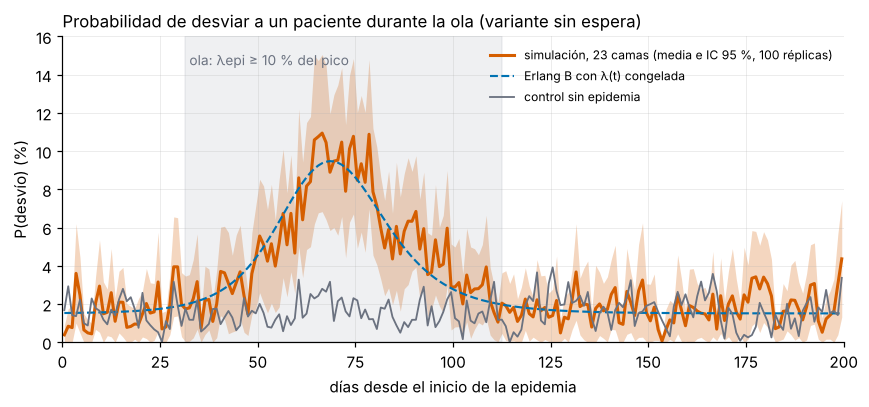

In [6]:
# 4.1b Probabilidad de bloqueo en función del tiempo (por día) con IC de 95 % entre réplicas
pb = LV.ic_por_columna([r["lleno_dia"] for r in reps_ola])
pb_ctrl = LV.ic_por_columna([r["lleno_dia"] for r in reps_ctrl])
tmed = DIA[:-1] + 0.5
lam_dia = np.array([np.mean([tasa(T_PRE + x) for x in np.linspace(d, d + 1, 11)]) for d in DIA[:-1]])
B_cuasi = np.array([T.erlang_b(REC, x / mu) for x in lam_dia])           # Erlang B "congelando" λ(t) en cada día
k_pico = int(np.argmax(pb["media"]))
curva_pb = pd.DataFrame({"dia": tmed, "lambda_t": lam_dia, "p_bloqueo": pb["media"], "ic_inf": pb["ic_inf"], "ic_sup": pb["ic_sup"],
                         "B_cuasiestacionario": B_cuasi, "p_bloqueo_sin_epidemia": pb_ctrl["media"],
                         "camas_ocupadas": np.mean([r["ocup_dia"] for r in reps_ola], axis=0)})
curva_pb.to_csv(DAT / "task4_1b_bloqueo_por_dia.csv", index=False)
RES["4.1b_pico_p_bloqueo"] = {"dia": float(tmed[k_pico]), "p": float(pb["media"][k_pico]), "ic": [float(pb["ic_inf"][k_pico]), float(pb["ic_sup"][k_pico])],
                              "B_cuasi_max": float(B_cuasi.max()), "dia_B_cuasi_max": float(tmed[int(np.argmax(B_cuasi))])}
print(f"- 4.1b P(bloqueo) máxima: {pb['media'][k_pico]:.4f} [{pb['ic_inf'][k_pico]:.4f}; {pb['ic_sup'][k_pico]:.4f}] en el día {tmed[k_pico]:.1f} "
      f"(Erlang B cuasiestacionario máximo {B_cuasi.max():.4f} en el día {tmed[int(np.argmax(B_cuasi))]:.1f})")
print(f"- 4.1b sin epidemia: P(bloqueo) media {pb_ctrl['media'].mean():.4f} (Erlang B(23) = {T.erlang_b(REC, lam / mu):.4f})")

# 4.1b Comprobación: desviados/llegadas por semana (conteos) frente a la fracción de tiempo llena (PASTA)
ns = np.sum([r["n_sem"] for r in reps_ola], axis=0); bs = np.sum([r["b_sem"] for r in reps_ola], axis=0)
semana_conteo = bs / ns
semana_tiempo = np.array([np.average(pb["media"][int(a):int(a) + 7], weights=lam_dia[int(a):int(a) + 7]) for a in SEM[:-1]])
dif = np.max(np.abs(semana_conteo - semana_tiempo))
RES["4.1b_comprobacion_semanal_max_dif"] = float(dif)
print(f"- 4.1b comprobación semanal: máxima diferencia entre Σb/Σn y la fracción llena ponderada por λ(t) = {dif:.4f}")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.fill_between(tmed, 100 * np.clip(pb["ic_inf"], 0, None), 100 * pb["ic_sup"], color=NARANJA, alpha=0.25, lw=0)
ax.plot(tmed, 100 * pb["media"], color=NARANJA, lw=2, label=f"simulación, {REC} camas (media e IC 95 %, 100 réplicas)")
ax.plot(tmed, 100 * B_cuasi, color=AZUL, lw=1.4, ls="--", label="Erlang B con λ(t) congelada")
ax.plot(tmed, 100 * pb_ctrl["media"], color=GRIS, lw=1.2, label="control sin epidemia")
ax.axvspan(*OLA, color=GRIS, alpha=0.10); ax.text(OLA[0] + 1, 14.5, "ola: λepi ≥ 10 % del pico", ha="left", color=GRIS, fontsize=9)
ax.set_xlim(0, DIAS); ax.set_xlabel("días desde el inicio de la epidemia"); ax.set_ylabel("P(desvío) (%)")
ax.set_title("Probabilidad de desviar a un paciente durante la ola (variante sin espera)", loc="left"); ax.set_ylim(0, 16); ax.legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.savefig(FIG / "fig_4_1b_bloqueo_tiempo.png", dpi=160); plt.show()

In [7]:
# 4.1b Total de pacientes desviados durante la ola y fracción desviada, con IC de 95 % (una observación por réplica)
def tabla_ventanas(reps):
    filas = []
    for nombre, (a0, a1) in VENTANAS.items():
        n = np.array([r[nombre][0] for r in reps]); b = np.array([r[nombre][1] for r in reps])
        ib, ifr, inn = S.ic_t(b), S.ic_t(b / n), S.ic_t(n)
        filas.append({"ventana": nombre, "días": f"{a0:.1f}-{a1:.1f}", "llegadas": inn["media"], "desviados": ib["media"],
                      "desviados IC inf": ib["ic_inf"], "desviados IC sup": ib["ic_sup"], "fracción desviada": ifr["media"],
                      "fracción IC inf": ifr["ic_inf"], "fracción IC sup": ifr["ic_sup"], "Σb/Σn": b.sum() / n.sum()})
    return pd.DataFrame(filas)

tab_ola = tabla_ventanas(reps_ola)
tab_ctrl = tabla_ventanas(reps_ctrl)
tab_ola["desviados sin epidemia (control)"] = tab_ctrl["desviados"].values
tab_ola["desviados sin epidemia (Erlang B)"] = [lam * (a1 - a0) * T.erlang_b(REC, lam / mu) for a0, a1 in VENTANAS.values()]
RES["4.1b_desviados"] = tab_ola.to_dict("records")
tab_ola.to_csv(DAT / "task4_1b_desviados.csv", index=False)
n_prev = np.array([r["previo"][0] for r in reps_ola]); b_prev = np.array([r["previo"][1] for r in reps_ola])
RES["4.1b_previo_30d"] = b_prev.sum() / n_prev.sum()
f = tab_ola.iloc[0]
print(f"- 4.1b durante la ola (días {f['días']}): {f['desviados']:.1f} desviados [{f['desviados IC inf']:.1f}; {f['desviados IC sup']:.1f}] "
      f"de {f['llegadas']:.0f} llegadas; fracción {f['fracción desviada']:.4f} [{f['fracción IC inf']:.4f}; {f['fracción IC sup']:.4f}]")
print(f"- 4.1b sin epidemia en la misma ventana: {f['desviados sin epidemia (control)']:.1f} desviados (Erlang B: {f['desviados sin epidemia (Erlang B)']:.1f})")
print(f"- 4.1b control de arranque: desvío en los 30 días previos a la epidemia = {RES['4.1b_previo_30d']:.4f} (Erlang B(23) = {T.erlang_b(REC, lam / mu):.4f})")
tab_ola.round(4)

- 4.1b durante la ola (días 31.5-112.5): 18.9 desviados [16.9; 20.9] de 362 llegadas; fracción 0.0517 [0.0465; 0.0569]
- 4.1b sin epidemia en la misma ventana: 5.1 desviados (Erlang B: 4.6)
- 4.1b control de arranque: desvío en los 30 días previos a la epidemia = 0.0168 (Erlang B(23) = 0.0151)


,ventana,días,llegadas,desviados,desviados IC inf,desviados IC sup,fracción desviada,fracción IC inf,fracción IC sup,Σb/Σn,desviados sin epidemia (control),desviados sin epidemia (Erlang B)
0,ola (λepi >= 10 % del pico),31.5-112.5,361.81,18.94,16.9430,20.9370,0.0517,0.0465,0.0569,0.0523,5.08,4.6417
1,200 días completos,0.0-200.0,817.27,27.32,24.8175,29.8225,0.0332,0.0302,0.0361,0.0334,12.53,11.4611
2,λepi >= 50 % del pico,50.3-88.7,185.75,13.42,11.7639,15.0761,0.0707,0.0625,0.0788,0.0722,2.44,2.2005


## Inciso 4.1c: camas de contingencia
Se busca el menor número $k$ de camas temporales con el que la fracción de pacientes desviados durante la ola no supere 5 %. Las $k$ camas se activan solo en la ventana de la ola (días 31.5 a 112.5), sobre las 23 permanentes; en el simulador es un "cierre" con $k_{off}=-k$.

**Criterio:** se exige que el **límite superior** del IC de 95 % de la fracción desviada sea ≤ 5 %, porque la directora pedirá presupuesto con este número y el costo de quedarse corto (pacientes críticos desviados en el pico) es mayor que el de una cama de más. También se reporta lo que daría la estimación puntual y la sensibilidad a la definición de la ola. Todas las corridas usan la misma semilla maestra (8401, números aleatorios comunes), así que las diferencias entre valores de $k$ no son ruido de llegadas distintas.

In [8]:
# 4.1c Barrido de camas temporales k (activas solo durante la ola) con el criterio IC sup <= 5 %
META_OLA = 0.05
barr, reps_k = [], {0: reps_ola}
for k in range(0, 5):
    if k not in reps_k:
        reps_k[k] = correr_ola(REC, extra=k)
    t_ = tabla_ventanas(reps_k[k]).set_index("ventana")
    fila = {"camas temporales k": k, "camas en la ola": REC + k}
    for nombre in VENTANAS:
        fila[f"{nombre}: fracción"] = t_.loc[nombre, "fracción desviada"]
        fila[f"{nombre}: IC sup"] = t_.loc[nombre, "fracción IC sup"]
    fila["desviados en la ola"] = t_.loc["ola (λepi >= 10 % del pico)", "desviados"]
    fila["P(bloqueo) diaria máxima"] = float(np.max(np.mean([r["lleno_dia"] for r in reps_k[k]], axis=0)))
    barr.append(fila)
barr = pd.DataFrame(barr)
col_f, col_s = "ola (λepi >= 10 % del pico): fracción", "ola (λepi >= 10 % del pico): IC sup"
k_min = int(barr.loc[barr[col_s] <= META_OLA, "camas temporales k"].min())
k_punto = int(barr.loc[barr[col_f] <= META_OLA, "camas temporales k"].min())
sens = {nombre: int(barr.loc[barr[f"{nombre}: IC sup"] <= META_OLA, "camas temporales k"].min()) for nombre in VENTANAS}
RES["4.1c_barrido"] = barr.to_dict("records")
RES["4.1c_k_min"] = {"criterio_IC_sup": k_min, "estimacion_puntual": k_punto, "sensibilidad_ventana": sens}
barr.to_csv(DAT / "task4_1c_camas_contingencia.csv", index=False)
print(f"- 4.1c menor k con IC sup de la fracción desviada en la ola <= 5 %: {k_min} (con la media puntual: {k_punto})")
print(f"- 4.1c sensibilidad a la ventana (IC sup <= 5 %): {sens}")
f0 = barr.iloc[k_min]
print(f"- 4.1c con {REC} + {k_min} camas: fracción {f0[col_f]:.4f} (IC sup {f0[col_s]:.4f}), {f0['desviados en la ola']:.1f} desviados en la ola, "
      f"P(bloqueo) diaria máxima {f0['P(bloqueo) diaria máxima']:.4f}")
barr.round(4)

- 4.1c menor k con IC sup de la fracción desviada en la ola <= 5 %: 1 (con la media puntual: 1)
- 4.1c sensibilidad a la ventana (IC sup <= 5 %): {'ola (λepi >= 10 % del pico)': 1, '200 días completos': 0, 'λepi >= 50 % del pico': 2}
- 4.1c con 23 + 1 camas: fracción 0.0378 (IC sup 0.0422), 13.8 desviados en la ola, P(bloqueo) diaria máxima 0.0914


,camas temporales k,camas en la ola,ola (λepi >= 10 % del pico): fracción,ola (λepi >= 10 % del pico): IC sup,200 días completos: fracción,200 días completos: IC sup,λepi >= 50 % del pico: fracción,λepi >= 50 % del pico: IC sup,desviados en la ola,P(bloqueo) diaria máxima
0,0,23,0.0517,0.0569,0.0332,0.0361,0.0707,0.0788,18.94,0.1094
1,1,24,0.0378,0.0422,0.0271,0.0298,0.0540,0.0612,13.84,0.0914
2,2,25,0.0268,0.0305,0.0225,0.0250,0.0394,0.0455,9.84,0.0780
3,3,26,0.0189,0.0221,0.0187,0.0210,0.0287,0.0340,6.94,0.0585
4,4,27,0.0133,0.0159,0.0158,0.0179,0.0209,0.0254,4.90,0.0414


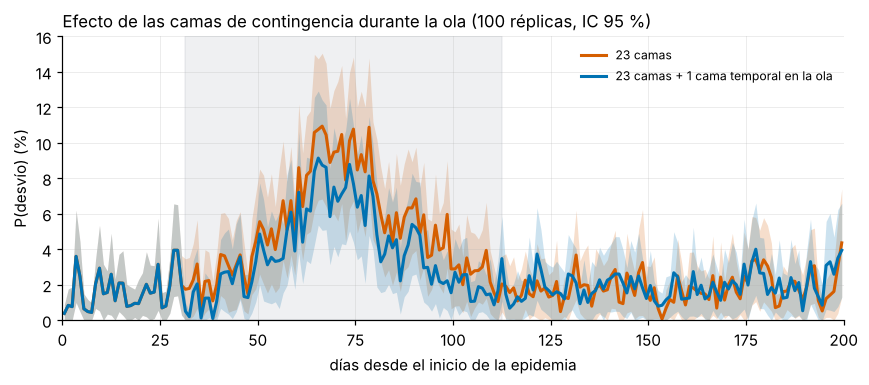

- Guardado: resultados/datos/task4_1bc_resultados.json y CSV de 4.1b-c


In [9]:
# 4.1c Figura: P(bloqueo) por día con 23 camas y con las camas de contingencia
fig, ax = plt.subplots(figsize=(8, 3.6))
for k, col in [(0, NARANJA), (k_min, AZUL)]:
    m = LV.ic_por_columna([r["lleno_dia"] for r in reps_k[k]])
    ax.fill_between(tmed, 100 * np.clip(m["ic_inf"], 0, None), 100 * m["ic_sup"], color=col, alpha=0.2, lw=0)
    ax.plot(tmed, 100 * m["media"], color=col, lw=2, label=f"{REC} camas" + (f" + {k} cama{'s' if k > 1 else ''} temporal{'es' if k > 1 else ''} en la ola" if k else ""))
ax.axvspan(*OLA, color=GRIS, alpha=0.10)
ax.set_xlim(0, DIAS); ax.set_xlabel("días desde el inicio de la epidemia"); ax.set_ylabel("P(desvío) (%)")
ax.set_ylim(0, 16); ax.set_title("Efecto de las camas de contingencia durante la ola (100 réplicas, IC 95 %)", loc="left"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "fig_4_1c_contingencia.png", dpi=160); plt.show()

(DAT / "task4_1bc_resultados.json").write_text(json.dumps({k: v for k, v in RES.items() if k.startswith(("4.1b", "4.1c"))}, indent=2, ensure_ascii=False,
    default=lambda o: o.item() if hasattr(o, "item") else (o.tolist() if hasattr(o, "tolist") else str(o))))
print("- Guardado: resultados/datos/task4_1bc_resultados.json y CSV de 4.1b-c")

## Inciso 4.1d — Límites del modelo de un solo sentido (pendiente)
Enumerar dos fenómenos que el modelo ignora (por ejemplo, qué le ocurre a la epidemia cuando el hospital desvía pacientes) y, para cada uno, la dirección en que cambiaría la estimación y por qué.